# K-Means Clustering: Understanding Unsupervised Learning Through Patient Utilization Cohorts

## Overview

This notebook explores **K-Means clustering**, one of the most fundamental unsupervised learning algorithms. We'll use a healthcare population-management context to understand how the algorithm automatically identifies groups in data and examine its behavior with outliers.

**Learning Objectives:**
- Understand how K-Means automatically discovers groups in unlabeled data
- Explore the algorithm's sensitivity to outliers
- Learn techniques to handle outliers in clustering
- Apply K-Means to real-world patient segmentation scenarios
- Understand when K-Means is appropriate and when alternative methods are needed

**Use Case:** Population Health Management - automatically segmenting a patient panel into utilization cohorts based on care-usage characteristics (visit frequency, length of stay, medication burden, annual cost) without prior labels.

> **A note on the data.** Every patient record in this notebook is simulated.
> No real or identifiable patient data is used.


## 1. Theoretical Foundation

### What is Unsupervised Learning?

Unlike supervised learning (where we have labels), **unsupervised learning** finds patterns in data without guidance:
- No pre-existing labels or categories
- Algorithm discovers natural groupings
- Useful for exploratory analysis and pattern discovery

### How K-Means Works

K-Means is an iterative algorithm that partitions data into K clusters:

1. **Initialization**: Randomly select K points as initial cluster centers (centroids)
2. **Assignment**: Assign each data point to the nearest centroid
3. **Update**: Recalculate centroids as the mean of all points in each cluster
4. **Repeat**: Steps 2-3 until centroids stabilize (convergence)

**Mathematical Objective:**

Minimize the within-cluster sum of squares (inertia):

$$J = \sum_{i=1}^{K} \sum_{x \in C_i} ||x - \mu_i||^2$$

Where:
- $K$ = number of clusters
- $C_i$ = set of points in cluster $i$
- $\mu_i$ = centroid of cluster $i$
- $||x - \mu_i||^2$ = squared Euclidean distance

### The Outlier Problem

K-Means uses **mean** calculations, making it sensitive to outliers:
- Outliers can pull centroids away from true cluster centers
- A single extreme point can distort entire cluster boundaries
- This is a fundamental limitation of distance-based clustering

In [1]:
# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, davies_bouldin_score
from ipywidgets import interact, IntSlider, FloatSlider, Checkbox
import warnings
warnings.filterwarnings('ignore')

# Set visualization style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 8)
np.random.seed(42)

## 2. Creating Synthetic Patient Utilization Data

We'll create a dataset representing three patient utilization cohorts with realistic care-usage characteristics:

- **Low Utilizers**: Few visits, short stays, few medications, low annual cost
- **Chronic Managed**: Moderate visits, moderate stays, moderate polypharmacy, moderate cost
- **High Utilizers**: Many visits, long stays, heavy polypharmacy, high annual cost

We'll also introduce outliers to simulate data-entry errors or genuinely extreme cases.

All values are simulated - no real or identifiable patient data is used.


In [2]:
def generate_patient_utilization_data(n_samples_per_class=100, add_outliers=True, n_outliers=10):
    """
    Generate synthetic patient utilization data with three distinct cohorts.

    Parameters:
    -----------
    n_samples_per_class : int
        Number of patients per cohort
    add_outliers : bool
        Whether to add outlier patients
    n_outliers : int
        Number of outlier patients to add

    Returns:
    --------
    DataFrame with patient utilization characteristics

    The values are simulated. No real or identifiable patient data is used.
    """

    # Low Utilizers: few visits, short stays, few medications, low annual cost
    low_utilizers = {
        'visits_per_year': np.random.normal(2, 0.7, n_samples_per_class),
        'mean_los_days': np.random.normal(0.4, 0.2, n_samples_per_class),
        'medication_count': np.random.normal(2, 1, n_samples_per_class),
        'annual_cost_cad': np.random.normal(1800, 400, n_samples_per_class),
        'true_type': ['Low Utilizer'] * n_samples_per_class
    }

    # Chronic Managed: moderate visits, moderate stays, moderate medication burden
    chronic_managed = {
        'visits_per_year': np.random.normal(10, 2, n_samples_per_class),
        'mean_los_days': np.random.normal(3.0, 0.8, n_samples_per_class),
        'medication_count': np.random.normal(8, 1.5, n_samples_per_class),
        'annual_cost_cad': np.random.normal(18000, 3500, n_samples_per_class),
        'true_type': ['Chronic Managed'] * n_samples_per_class
    }

    # High Utilizers: many visits, long stays, polypharmacy, high annual cost
    high_utilizers = {
        'visits_per_year': np.random.normal(28, 5, n_samples_per_class),
        'mean_los_days': np.random.normal(9.0, 2.0, n_samples_per_class),
        'medication_count': np.random.normal(15, 2, n_samples_per_class),
        'annual_cost_cad': np.random.normal(110000, 20000, n_samples_per_class),
        'true_type': ['High Utilizer'] * n_samples_per_class
    }

    # Combine all cohorts
    patients = pd.DataFrame({
        'visits_per_year': np.concatenate([low_utilizers['visits_per_year'],
                                           chronic_managed['visits_per_year'],
                                           high_utilizers['visits_per_year']]),
        'mean_los_days': np.concatenate([low_utilizers['mean_los_days'],
                                         chronic_managed['mean_los_days'],
                                         high_utilizers['mean_los_days']]),
        'medication_count': np.concatenate([low_utilizers['medication_count'],
                                            chronic_managed['medication_count'],
                                            high_utilizers['medication_count']]),
        'annual_cost_cad': np.concatenate([low_utilizers['annual_cost_cad'],
                                           chronic_managed['annual_cost_cad'],
                                           high_utilizers['annual_cost_cad']]),
        'true_type': low_utilizers['true_type'] + chronic_managed['true_type'] + high_utilizers['true_type']
    })

    # Add outliers if requested (data-entry errors or genuinely extreme cases)
    if add_outliers:
        outliers = pd.DataFrame({
            'visits_per_year': np.random.uniform(0, 60, n_outliers),
            'mean_los_days': np.random.uniform(0, 45, n_outliers),
            'medication_count': np.random.uniform(0, 30, n_outliers),
            'annual_cost_cad': np.random.uniform(500, 400000, n_outliers),
            'true_type': ['Outlier'] * n_outliers
        })
        patients = pd.concat([patients, outliers], ignore_index=True)

    # Utilization counts and costs cannot be negative
    patients['visits_per_year'] = patients['visits_per_year'].clip(lower=0)
    patients['mean_los_days'] = patients['mean_los_days'].clip(lower=0)
    patients['medication_count'] = patients['medication_count'].clip(lower=0)
    patients['annual_cost_cad'] = patients['annual_cost_cad'].clip(lower=0)

    return patients

# Generate the dataset
patient_data = generate_patient_utilization_data(n_samples_per_class=100, add_outliers=True, n_outliers=15)

print(f"Dataset shape: {patient_data.shape}")
print(f"\nCohort distribution:")
print(patient_data['true_type'].value_counts())
print(f"\nFirst few rows:")
patient_data.head(10)


Dataset shape: (315, 5)

Cohort distribution:
true_type
Low Utilizer       100
Chronic Managed    100
High Utilizer      100
Outlier             15
Name: count, dtype: int64

First few rows:


,visits_per_year,mean_los_days,medication_count,annual_cost_cad,true_type
0,2.347700,0.116926,2.357787,1468.401996,Low Utilizer
1,1.903215,0.315871,2.560785,1575.927584,Low Utilizer
2,2.453382,0.331457,3.083051,2098.917442,Low Utilizer
3,3.066121,0.239545,3.053802,2044.148106,Low Utilizer
4,1.836093,0.367743,0.622331,1791.639362,Low Utilizer
5,1.836104,0.480810,1.062175,1846.930953,Low Utilizer
6,3.105449,0.777237,2.515035,2311.065958,Low Utilizer
7,2.537204,0.434916,2.513786,1563.371444,Low Utilizer
8,1.671368,0.451510,2.515048,2018.838952,Low Utilizer
9,2.379792,0.385111,5.852731,1719.122939,Low Utilizer


In [3]:
# Statistical summary
patient_data.groupby('true_type').agg({
    'visits_per_year': ['mean', 'std'],
    'mean_los_days': ['mean', 'std'],
    'medication_count': ['mean', 'std'],
    'annual_cost_cad': ['mean', 'std']
}).round(2)

visits_per_year        mean_los_days        medication_count  \
                           mean    std          mean    std             mean   
true_type                                                                      
Chronic Managed            9.89   2.13          2.91   0.74             8.04   
High Utilizer             29.14   4.69          9.06   1.94            15.32   
Low Utilizer               1.93   0.64          0.40   0.19             2.08   
Outlier                   34.02  17.89         20.08  12.74            16.10   

                      annual_cost_cad             
                  std            mean        std  
true_type                                         
Chronic Managed  1.60        17978.44    3411.62  
High Utilizer    1.90       112141.83   22176.34  
Low Utilizer     1.05         1842.74     353.64  
Outlier          7.91       141486.45  113420.25

## 3. Visualizing the Data

Let's visualize the patient utilization characteristics to understand the natural groupings and outliers.


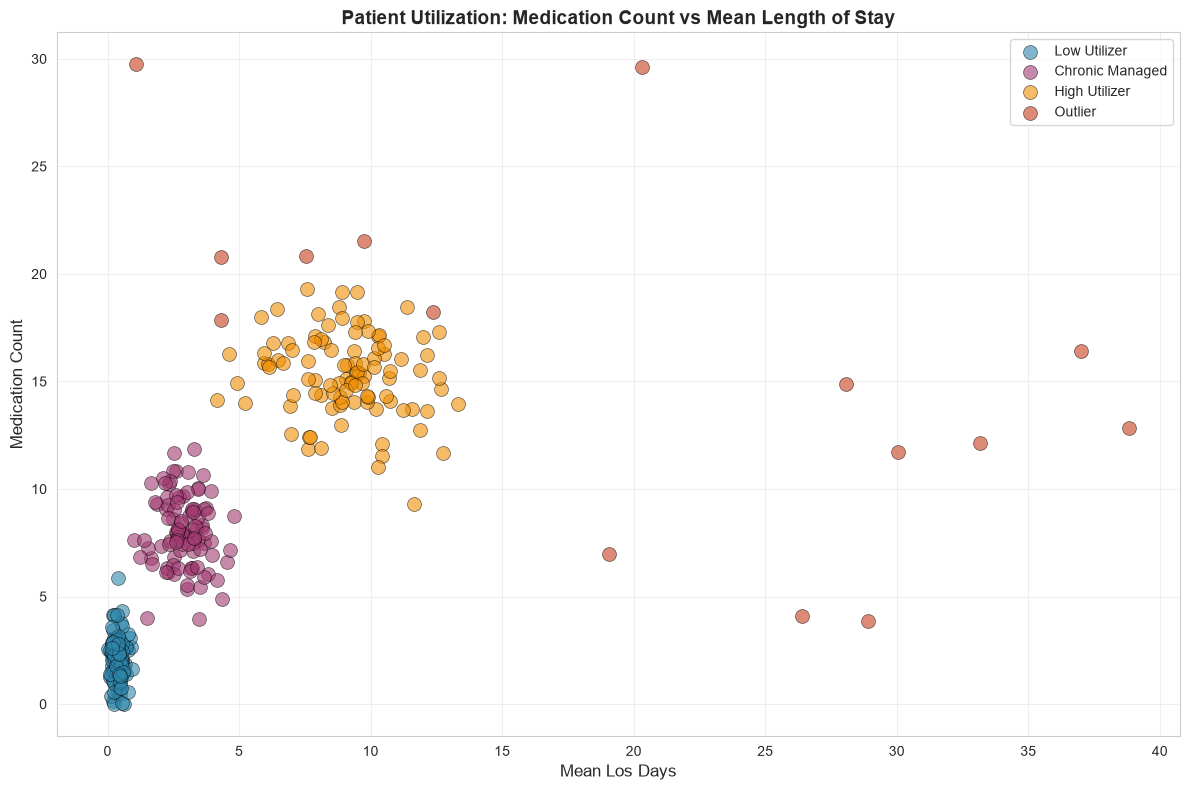

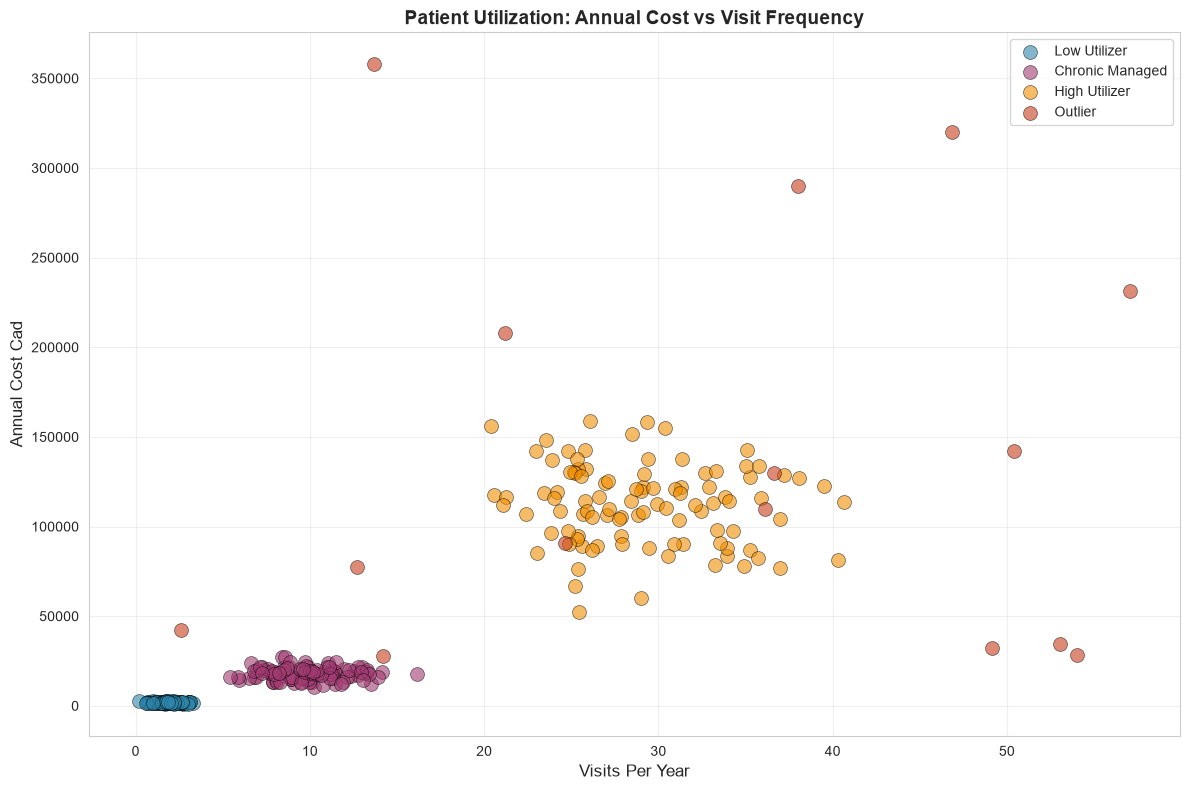

In [4]:
def plot_patient_scatter(data, x_col, y_col, title=None):
    """
    Create a scatter plot of patient data colored by true cohort.
    """
    fig, ax = plt.subplots(figsize=(12, 8))
    
    colors = {'Low Utilizer': '#2E86AB', 'Chronic Managed': '#A23B72', 
              'High Utilizer': '#F18F01', 'Outlier': '#C73E1D'}
    
    for cohort_name in data['true_type'].unique():
        subset = data[data['true_type'] == cohort_name]
        ax.scatter(subset[x_col], subset[y_col], 
                  c=colors[cohort_name], label=cohort_name, 
                  alpha=0.6, s=100, edgecolors='black', linewidth=0.5)
    
    ax.set_xlabel(x_col.replace('_', ' ').title(), fontsize=12)
    ax.set_ylabel(y_col.replace('_', ' ').title(), fontsize=12)
    ax.set_title(title or f'{y_col} vs {x_col}', fontsize=14, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    return fig

# Create multiple views of the data
plot_patient_scatter(patient_data, 'mean_los_days', 'medication_count',
                   'Patient Utilization: Medication Count vs Mean Length of Stay')
plt.show()

plot_patient_scatter(patient_data, 'visits_per_year', 'annual_cost_cad',
                   'Patient Utilization: Annual Cost vs Visit Frequency')
plt.show()

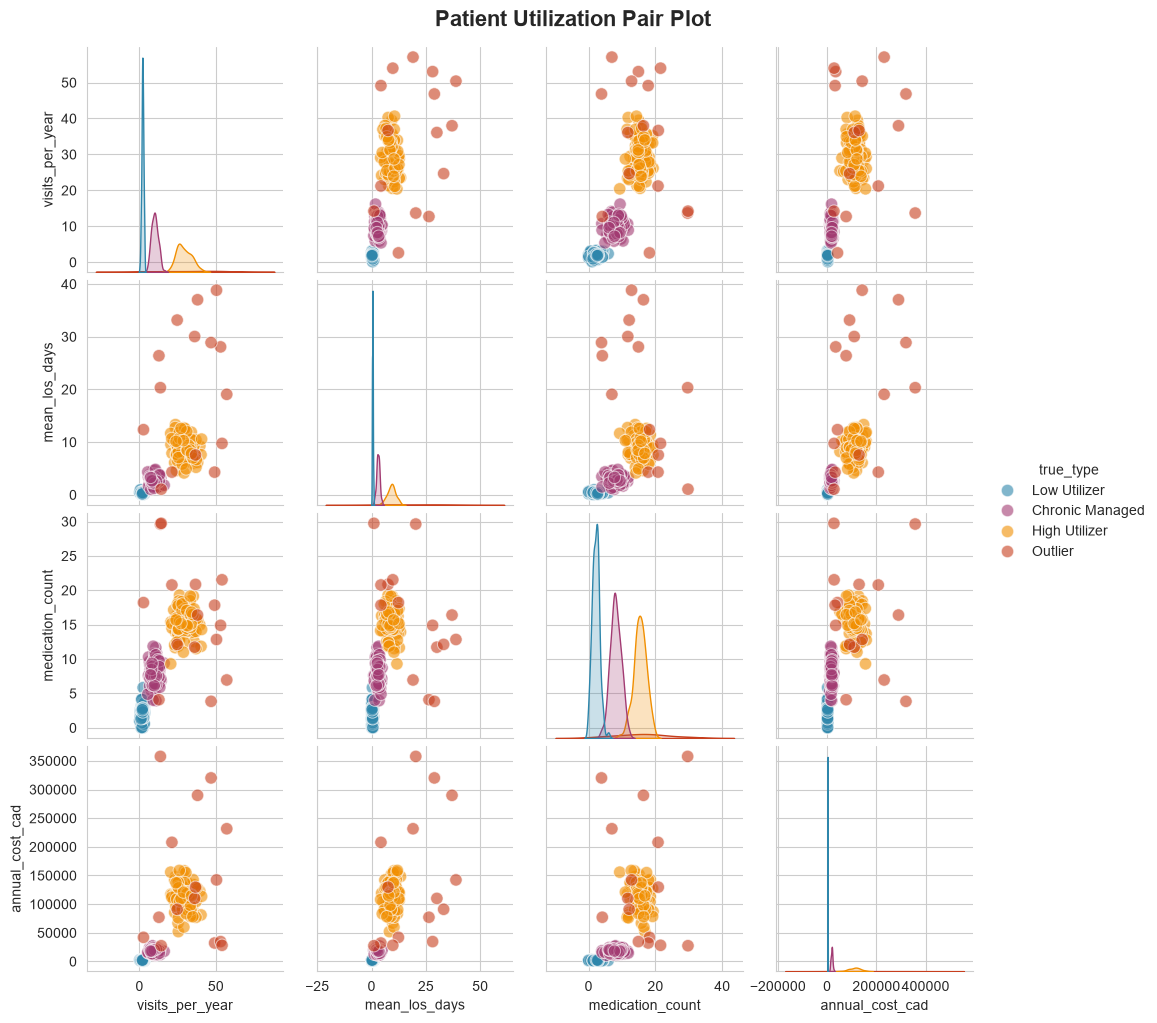

In [5]:
# Pair plot for comprehensive view
feature_cols = ['visits_per_year', 'mean_los_days', 
                'medication_count', 'annual_cost_cad']

colors = {'Low Utilizer': '#2E86AB', 'Chronic Managed': '#A23B72', 
          'High Utilizer': '#F18F01', 'Outlier': '#C73E1D'}

g = sns.pairplot(patient_data, vars=feature_cols, hue='true_type', 
                palette=colors, diag_kind='kde', plot_kws={'alpha': 0.6, 's': 80})
g.fig.suptitle('Patient Utilization Pair Plot', y=1.02, fontsize=16, fontweight='bold')
plt.show()

## 4. K-Means Clustering Without Outlier Handling

First, let's apply K-Means directly to see how outliers affect the clustering.

**Important:** K-Means is sensitive to feature scales, so we'll standardize the data first.

In [6]:
# Prepare features for clustering
X = patient_data[feature_cols].values

# Standardize features (important for K-Means)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Feature scaling summary:")
print(f"Original data range: {X.min():.2f} to {X.max():.2f}")
print(f"Scaled data range: {X_scaled.min():.2f} to {X_scaled.max():.2f}")
print(f"Scaled data mean: {X_scaled.mean():.6f}")
print(f"Scaled data std: {X_scaled.std():.6f}")

Feature scaling summary:
Original data range: 0.00 to 357729.25
Scaled data range: -1.48 to 5.94
Scaled data mean: -0.000000
Scaled data std: 1.000000


In [7]:
# Apply K-Means with K=3 (we know there are 3 cohorts)
kmeans_with_outliers = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_with_outliers = kmeans_with_outliers.fit_predict(X_scaled)

# Add cluster assignments to dataframe
patient_data['cluster_with_outliers'] = clusters_with_outliers

print(f"Inertia (within-cluster sum of squares): {kmeans_with_outliers.inertia_:.2f}")
print(f"\nCluster sizes:")
print(patient_data['cluster_with_outliers'].value_counts().sort_index())

Inertia (within-cluster sum of squares): 252.23

Cluster sizes:
cluster_with_outliers
0    200
1      9
2    106
Name: count, dtype: int64


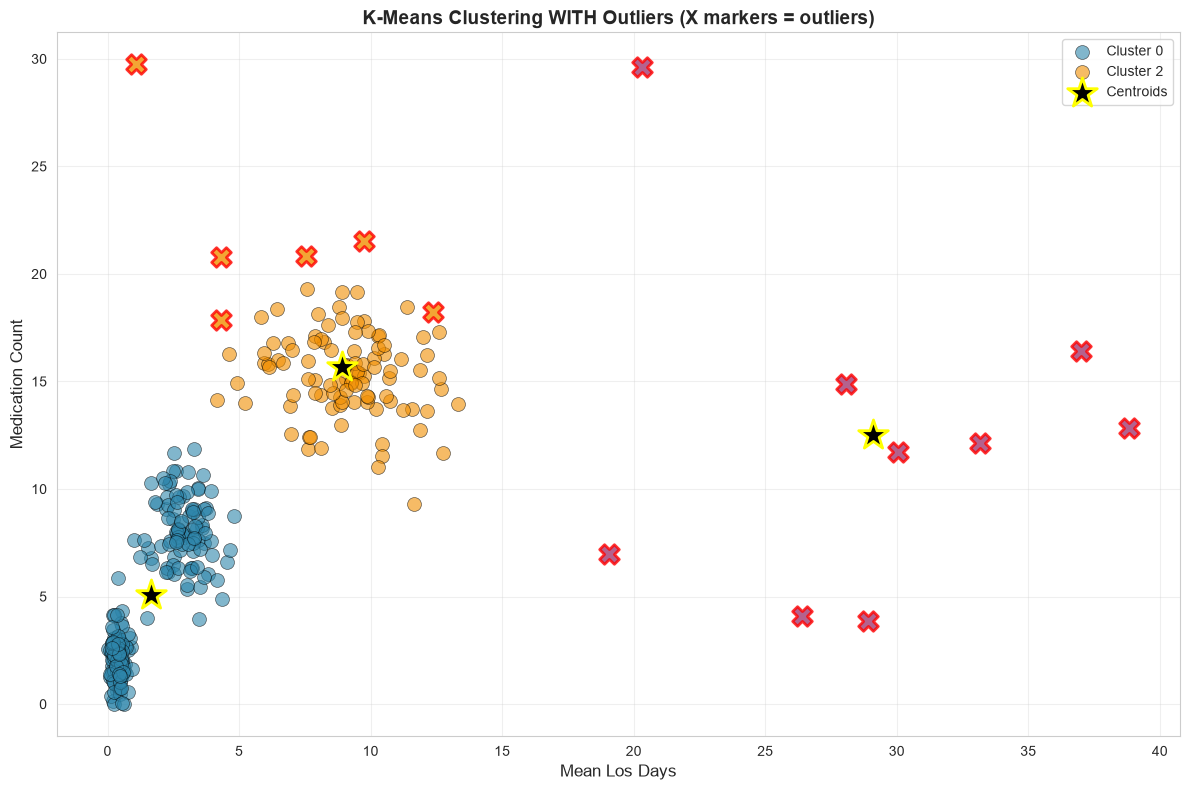

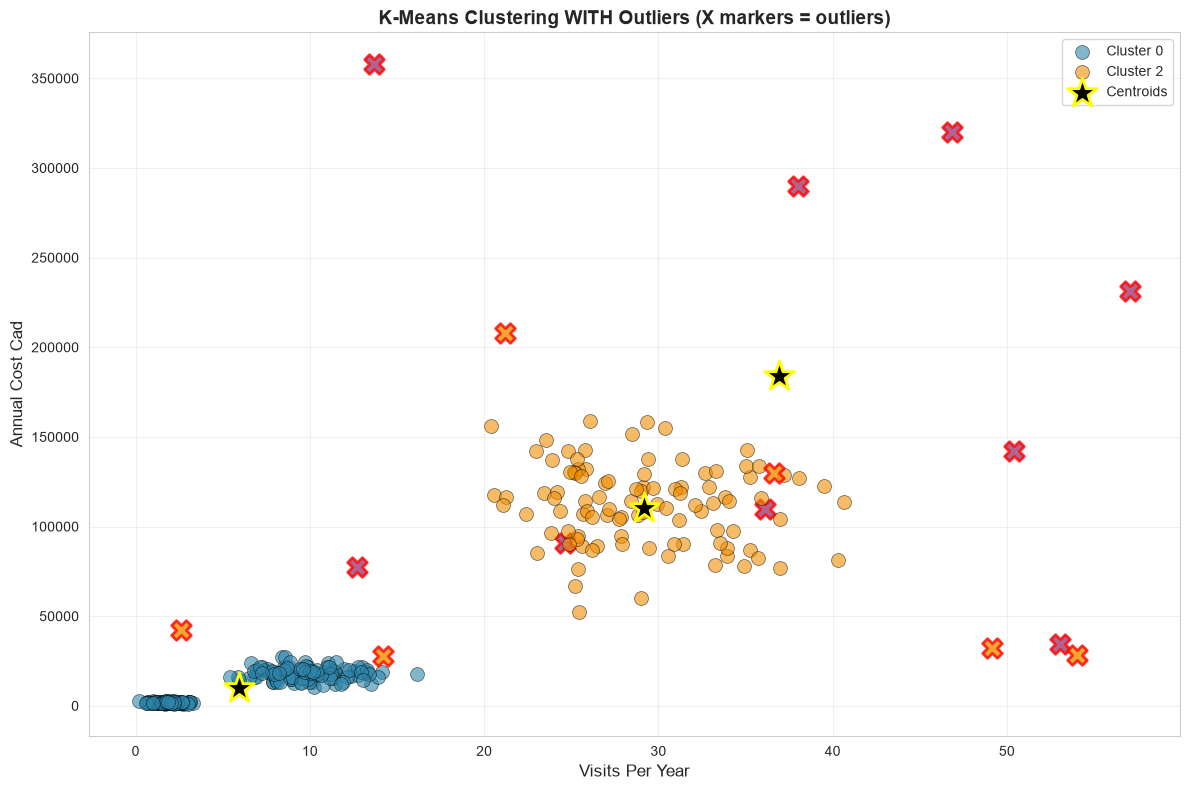

In [8]:
def plot_clusters(data, x_col, y_col, cluster_col, centroids=None, title=None):
    """
    Visualize clustering results.
    """
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Get column indices for plotting centroids
    x_idx = feature_cols.index(x_col)
    y_idx = feature_cols.index(y_col)
    
    # Plot points colored by cluster
    cluster_colors = ['#2E86AB', '#A23B72', '#F18F01']
    
    for cluster_id in sorted(data[cluster_col].unique()):
        cluster_data = data[data[cluster_col] == cluster_id]
        
        # Separate outliers from the main cohorts
        outliers_in_cluster = cluster_data[cluster_data['true_type'] == 'Outlier']
        normal_in_cluster = cluster_data[cluster_data['true_type'] != 'Outlier']
        
        # Plot normal patients
        if len(normal_in_cluster) > 0:
            ax.scatter(normal_in_cluster[x_col], normal_in_cluster[y_col],
                      c=cluster_colors[cluster_id], label=f'Cluster {cluster_id}',
                      alpha=0.6, s=100, edgecolors='black', linewidth=0.5)
        
        # Plot outliers with different marker
        if len(outliers_in_cluster) > 0:
            ax.scatter(outliers_in_cluster[x_col], outliers_in_cluster[y_col],
                      c=cluster_colors[cluster_id], marker='X', s=200,
                      edgecolors='red', linewidth=2, alpha=0.8)
    
    # Plot centroids if provided
    if centroids is not None:
        # Transform centroids back to original scale
        centroids_original = scaler.inverse_transform(centroids)
        ax.scatter(centroids_original[:, x_idx], centroids_original[:, y_idx],
                  c='black', marker='*', s=500, edgecolors='yellow',
                  linewidth=2, label='Centroids', zorder=10)
    
    ax.set_xlabel(x_col.replace('_', ' ').title(), fontsize=12)
    ax.set_ylabel(y_col.replace('_', ' ').title(), fontsize=12)
    ax.set_title(title or 'K-Means Clustering Results', fontsize=14, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    return fig

# Visualize clustering with outliers
plot_clusters(patient_data, 'mean_los_days', 'medication_count',
             'cluster_with_outliers', kmeans_with_outliers.cluster_centers_,
             'K-Means Clustering WITH Outliers (X markers = outliers)')
plt.show()

plot_clusters(patient_data, 'visits_per_year', 'annual_cost_cad',
             'cluster_with_outliers', kmeans_with_outliers.cluster_centers_,
             'K-Means Clustering WITH Outliers (X markers = outliers)')
plt.show()

### Analyzing Cluster Quality

We'll use two metrics to evaluate clustering quality:

1. **Silhouette Score** (-1 to 1): Measures how similar points are to their own cluster vs. other clusters. Higher is better.
2. **Davies-Bouldin Index** (0 to ∞): Ratio of within-cluster to between-cluster distances. Lower is better.

In [9]:
# Calculate clustering metrics
silhouette_with_outliers = silhouette_score(X_scaled, clusters_with_outliers)
davies_bouldin_with_outliers = davies_bouldin_score(X_scaled, clusters_with_outliers)

print("Clustering Quality Metrics (WITH outliers):")
print(f"Silhouette Score: {silhouette_with_outliers:.4f} (higher is better, range: -1 to 1)")
print(f"Davies-Bouldin Index: {davies_bouldin_with_outliers:.4f} (lower is better, range: 0 to ∞)")

# Confusion matrix: true types vs clusters
print("\nCross-tabulation of True Types vs Cluster Assignments:")
confusion = pd.crosstab(patient_data['true_type'], patient_data['cluster_with_outliers'], 
                        margins=True, margins_name='Total')
print(confusion)

Clustering Quality Metrics (WITH outliers):
Silhouette Score: 0.7079 (higher is better, range: -1 to 1)
Davies-Bouldin Index: 0.7712 (lower is better, range: 0 to ∞)

Cross-tabulation of True Types vs Cluster Assignments:
cluster_with_outliers    0  1    2  Total
true_type                                
Chronic Managed        100  0    0    100
High Utilizer            0  0  100    100
Low Utilizer           100  0    0    100
Outlier                  0  9    6     15
Total                  200  9  106    315


## 5. K-Means Clustering WITH Outlier Removal

Now let's remove outliers and see how clustering improves. We'll use a simple approach:
- Remove points that are far from all cluster centers (high distance to nearest centroid)
- This is a common preprocessing technique for K-Means

In [10]:
def remove_outliers_kmeans(X, percentile=95):
    """
    Remove outliers using distance to nearest centroid.
    
    Parameters:
    -----------
    X : array
        Feature matrix
    percentile : float
        Percentile threshold for outlier detection
    
    Returns:
    --------
    mask : boolean array
        True for inliers, False for outliers
    """
    # Fit initial K-Means
    kmeans_temp = KMeans(n_clusters=3, random_state=42, n_init=10)
    kmeans_temp.fit(X)
    
    # Calculate distance to nearest centroid for each point
    distances = np.min(kmeans_temp.transform(X), axis=1)
    
    # Set threshold at specified percentile
    threshold = np.percentile(distances, percentile)
    
    # Create mask for inliers
    inlier_mask = distances <= threshold
    
    print(f"Outlier removal summary:")
    print(f"Distance threshold (at {percentile}th percentile): {threshold:.4f}")
    print(f"Points removed: {(~inlier_mask).sum()} ({100 * (~inlier_mask).sum() / len(X):.1f}%)")
    print(f"Points retained: {inlier_mask.sum()} ({100 * inlier_mask.sum() / len(X):.1f}%)")
    
    return inlier_mask, distances

# Remove outliers
inlier_mask, distances_to_centroid = remove_outliers_kmeans(X_scaled, percentile=95)

# Check what we removed
print("\nTypes of patients removed:")
print(patient_data.loc[~inlier_mask, 'true_type'].value_counts())

Outlier removal summary:
Distance threshold (at 95th percentile): 1.2017
Points removed: 16 (5.1%)
Points retained: 299 (94.9%)

Types of patients removed:
true_type
Outlier          14
High Utilizer     2
Name: count, dtype: int64


In [11]:
# Apply K-Means to cleaned data
X_scaled_clean = X_scaled[inlier_mask]
patient_data_clean = patient_data[inlier_mask].copy()

kmeans_clean = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters_clean = kmeans_clean.fit_predict(X_scaled_clean)

patient_data_clean['cluster_clean'] = clusters_clean

print(f"Inertia (within-cluster sum of squares): {kmeans_clean.inertia_:.2f}")
print(f"\nCluster sizes:")
print(patient_data_clean['cluster_clean'].value_counts().sort_index())

Inertia (within-cluster sum of squares): 61.60

Cluster sizes:
cluster_clean
0     99
1     99
2    101
Name: count, dtype: int64


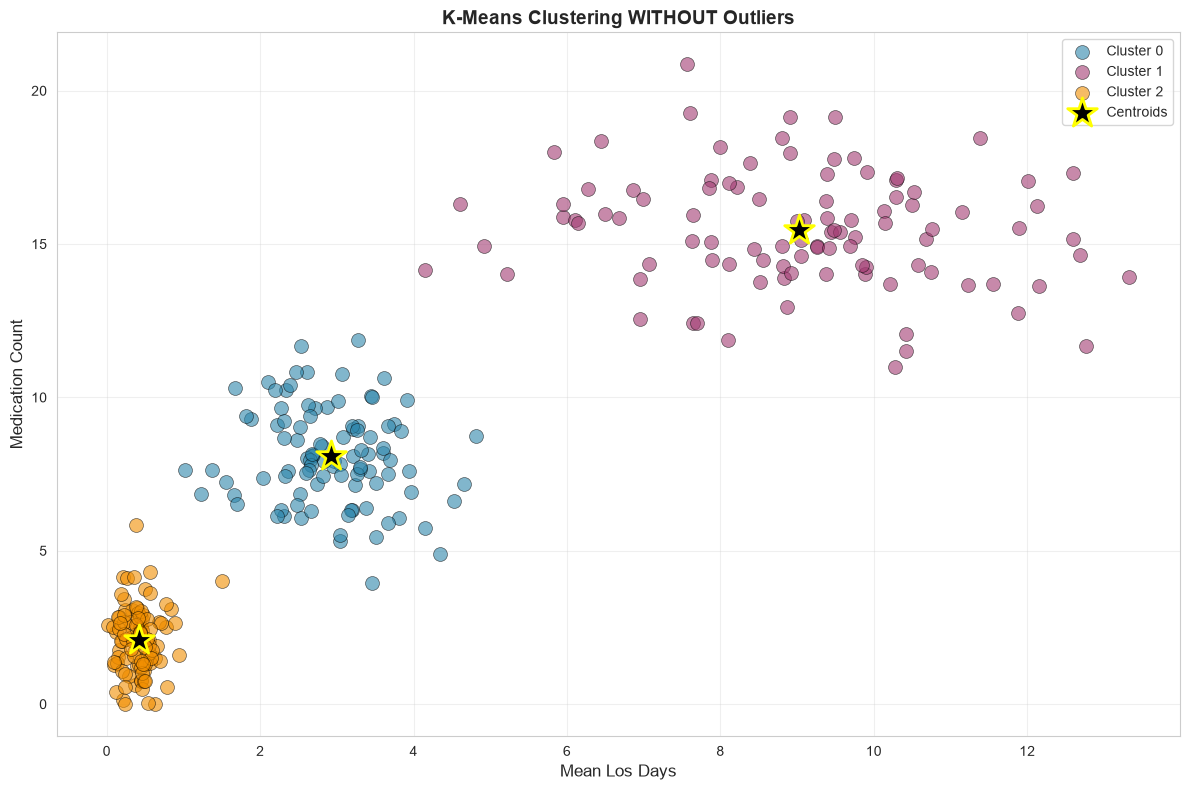

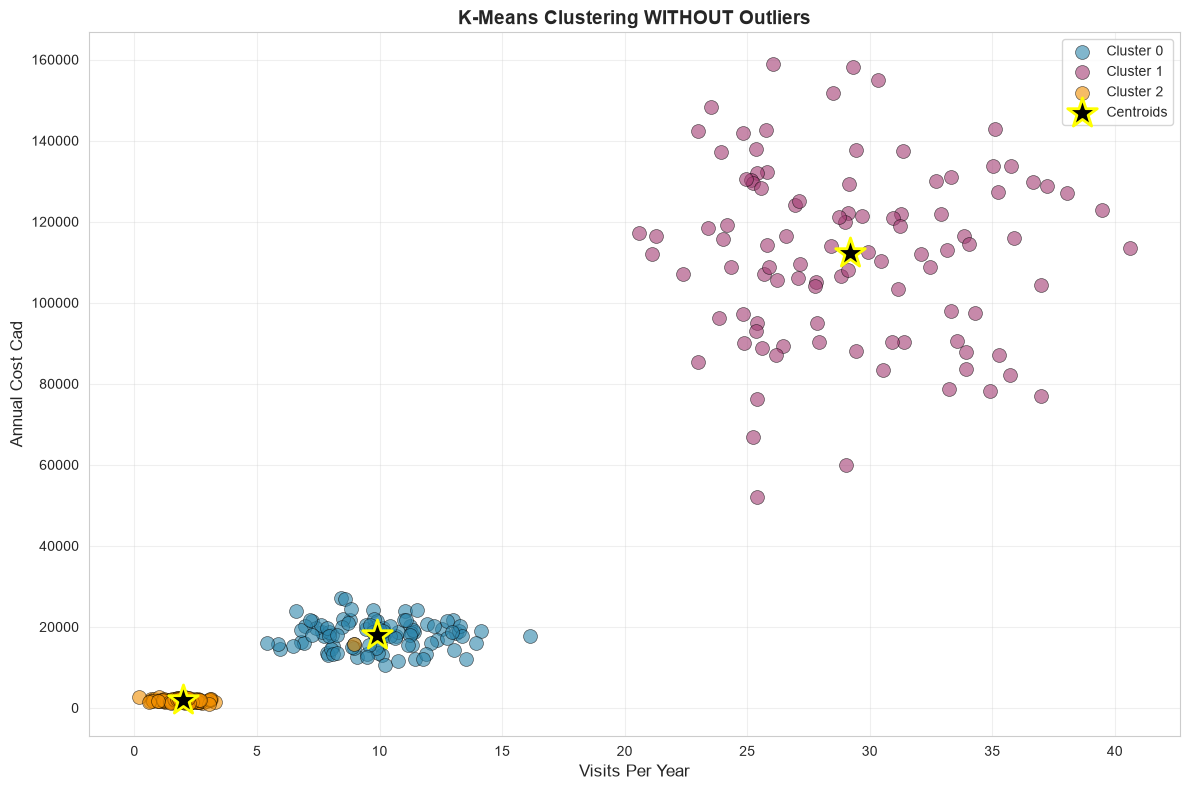

In [12]:
# Visualize clustering without outliers
def plot_clusters_clean(data, x_col, y_col, cluster_col, centroids=None, title=None):
    """
    Visualize clustering results for cleaned data.
    """
    fig, ax = plt.subplots(figsize=(12, 8))
    
    # Get column indices
    x_idx = feature_cols.index(x_col)
    y_idx = feature_cols.index(y_col)
    
    # Plot points colored by cluster
    cluster_colors = ['#2E86AB', '#A23B72', '#F18F01']
    
    for cluster_id in sorted(data[cluster_col].unique()):
        cluster_data = data[data[cluster_col] == cluster_id]
        ax.scatter(cluster_data[x_col], cluster_data[y_col],
                  c=cluster_colors[cluster_id], label=f'Cluster {cluster_id}',
                  alpha=0.6, s=100, edgecolors='black', linewidth=0.5)
    
    # Plot centroids if provided
    if centroids is not None:
        centroids_original = scaler.inverse_transform(centroids)
        ax.scatter(centroids_original[:, x_idx], centroids_original[:, y_idx],
                  c='black', marker='*', s=500, edgecolors='yellow',
                  linewidth=2, label='Centroids', zorder=10)
    
    ax.set_xlabel(x_col.replace('_', ' ').title(), fontsize=12)
    ax.set_ylabel(y_col.replace('_', ' ').title(), fontsize=12)
    ax.set_title(title or 'K-Means Clustering Results', fontsize=14, fontweight='bold')
    ax.legend(loc='best', fontsize=10)
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    return fig

plot_clusters_clean(patient_data_clean, 'mean_los_days', 'medication_count',
                   'cluster_clean', kmeans_clean.cluster_centers_,
                   'K-Means Clustering WITHOUT Outliers')
plt.show()

plot_clusters_clean(patient_data_clean, 'visits_per_year', 'annual_cost_cad',
                   'cluster_clean', kmeans_clean.cluster_centers_,
                   'K-Means Clustering WITHOUT Outliers')
plt.show()

In [13]:
# Calculate metrics for cleaned clustering
silhouette_clean = silhouette_score(X_scaled_clean, clusters_clean)
davies_bouldin_clean = davies_bouldin_score(X_scaled_clean, clusters_clean)

print("Clustering Quality Metrics (WITHOUT outliers):")
print(f"Silhouette Score: {silhouette_clean:.4f} (higher is better)")
print(f"Davies-Bouldin Index: {davies_bouldin_clean:.4f} (lower is better)")

print("\n" + "="*50)
print("COMPARISON: WITH vs WITHOUT Outliers")
print("="*50)
print(f"Silhouette Score:")
print(f"  With outliers:    {silhouette_with_outliers:.4f}")
print(f"  Without outliers: {silhouette_clean:.4f}")
print(f"  Improvement:      {((silhouette_clean - silhouette_with_outliers) / abs(silhouette_with_outliers)) * 100:.1f}%")

print(f"\nDavies-Bouldin Index:")
print(f"  With outliers:    {davies_bouldin_with_outliers:.4f}")
print(f"  Without outliers: {davies_bouldin_clean:.4f}")
print(f"  Improvement:      {((davies_bouldin_with_outliers - davies_bouldin_clean) / davies_bouldin_with_outliers) * 100:.1f}%")

# Cross-tabulation for cleaned data
print("\nCross-tabulation of True Types vs Cluster Assignments (cleaned):")
confusion_clean = pd.crosstab(patient_data_clean['true_type'], patient_data_clean['cluster_clean'],
                              margins=True, margins_name='Total')
print(confusion_clean)

Clustering Quality Metrics (WITHOUT outliers):
Silhouette Score: 0.7156 (higher is better)
Davies-Bouldin Index: 0.3622 (lower is better)

COMPARISON: WITH vs WITHOUT Outliers
Silhouette Score:
  With outliers:    0.7079
  Without outliers: 0.7156
  Improvement:      1.1%

Davies-Bouldin Index:
  With outliers:    0.7712
  Without outliers: 0.3622
  Improvement:      53.0%

Cross-tabulation of True Types vs Cluster Assignments (cleaned):
cluster_clean     0   1    2  Total
true_type                          
Chronic Managed  99   0    1    100
High Utilizer     0  98    0     98
Low Utilizer      0   0  100    100
Outlier           0   1    0      1
Total            99  99  101    299


## 6. Interactive Exploration: Impact of Outliers

Use the interactive widgets below to explore how different numbers of outliers affect clustering performance.

In [14]:
def explore_outlier_impact(n_outliers=15, outlier_percentile=95, show_comparison=True):
    """
    Interactive function to explore the impact of outliers on K-Means clustering.
    """
    # Generate new data with specified number of outliers
    data = generate_patient_utilization_data(n_samples_per_class=100, 
                                add_outliers=True, 
                                n_outliers=n_outliers)
    
    X = data[feature_cols].values
    X_scaled = scaler.fit_transform(X)
    
    # Cluster with outliers
    kmeans_with = KMeans(n_clusters=3, random_state=42, n_init=10)
    clusters_with = kmeans_with.fit_predict(X_scaled)
    
    # Remove outliers and cluster
    inlier_mask, _ = remove_outliers_kmeans(X_scaled, percentile=outlier_percentile)
    X_scaled_clean = X_scaled[inlier_mask]
    data_clean = data[inlier_mask].copy()
    
    kmeans_without = KMeans(n_clusters=3, random_state=42, n_init=10)
    clusters_without = kmeans_without.fit_predict(X_scaled_clean)
    
    # Calculate metrics
    sil_with = silhouette_score(X_scaled, clusters_with)
    db_with = davies_bouldin_score(X_scaled, clusters_with)
    
    sil_without = silhouette_score(X_scaled_clean, clusters_without)
    db_without = davies_bouldin_score(X_scaled_clean, clusters_without)
    
    if show_comparison:
        # Create comparison plots
        fig, axes = plt.subplots(1, 2, figsize=(18, 6))
        
        # With outliers
        data['cluster'] = clusters_with
        for cluster_id in range(3):
            cluster_data = data[data['cluster'] == cluster_id]
            outliers = cluster_data[cluster_data['true_type'] == 'Outlier']
            normal = cluster_data[cluster_data['true_type'] != 'Outlier']
            
            if len(normal) > 0:
                axes[0].scatter(normal['mean_los_days'], 
                              normal['medication_count'],
                              alpha=0.6, s=100, edgecolors='black', linewidth=0.5)
            if len(outliers) > 0:
                axes[0].scatter(outliers['mean_los_days'], 
                              outliers['medication_count'],
                              marker='X', s=200, edgecolors='red', linewidth=2)
        
        # Plot centroids
        centroids_orig = scaler.inverse_transform(kmeans_with.cluster_centers_)
        axes[0].scatter(centroids_orig[:, 1], centroids_orig[:, 2],
                       c='black', marker='*', s=500, edgecolors='yellow', linewidth=2)
        
        axes[0].set_xlabel('Mean Length of Stay (days)', fontsize=11)
        axes[0].set_ylabel('Medication Count', fontsize=11)
        axes[0].set_title(f'WITH Outliers (n={n_outliers})\nSilhouette: {sil_with:.3f}, DB: {db_with:.3f}',
                         fontsize=12, fontweight='bold')
        axes[0].grid(True, alpha=0.3)
        
        # Without outliers
        data_clean['cluster'] = clusters_without
        for cluster_id in range(3):
            cluster_data = data_clean[data_clean['cluster'] == cluster_id]
            axes[1].scatter(cluster_data['mean_los_days'], 
                          cluster_data['medication_count'],
                          alpha=0.6, s=100, edgecolors='black', linewidth=0.5)
        
        centroids_orig_clean = scaler.inverse_transform(kmeans_without.cluster_centers_)
        axes[1].scatter(centroids_orig_clean[:, 1], centroids_orig_clean[:, 2],
                       c='black', marker='*', s=500, edgecolors='yellow', linewidth=2)
        
        axes[1].set_xlabel('Mean Length of Stay (days)', fontsize=11)
        axes[1].set_ylabel('Medication Count', fontsize=11)
        axes[1].set_title(f'WITHOUT Outliers (removed {n_outliers - inlier_mask.sum()} points)\nSilhouette: {sil_without:.3f}, DB: {db_without:.3f}',
                         fontsize=12, fontweight='bold')
        axes[1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()
    
    # Print summary
    print(f"\nOutliers Impact Summary:")
    print(f"Number of outliers added: {n_outliers}")
    print(f"Number of points removed: {(~inlier_mask).sum()}")
    print(f"\nMetric improvements after outlier removal:")
    print(f"Silhouette Score: {sil_with:.4f} → {sil_without:.4f} ({((sil_without-sil_with)/abs(sil_with)*100):.1f}% improvement)")
    print(f"Davies-Bouldin Index: {db_with:.4f} → {db_without:.4f} ({((db_with-db_without)/db_with*100):.1f}% improvement)")

# Create interactive widget
interact(explore_outlier_impact,
         n_outliers=IntSlider(min=0, max=50, step=5, value=15, description='Outliers:'),
         outlier_percentile=IntSlider(min=90, max=99, step=1, value=95, description='Percentile:'),
         show_comparison=Checkbox(value=True, description='Show plots'));

interactive(children=(IntSlider(value=15, description='Outliers:', max=50, step=5), IntSlider(value=95, descri…

## 7. Determining Optimal K: The Elbow Method

In practice, we don't always know the true number of clusters. The **Elbow Method** helps us choose K by plotting inertia vs. number of clusters and looking for an "elbow" where the rate of decrease slows.

Analysis on data WITH outliers:


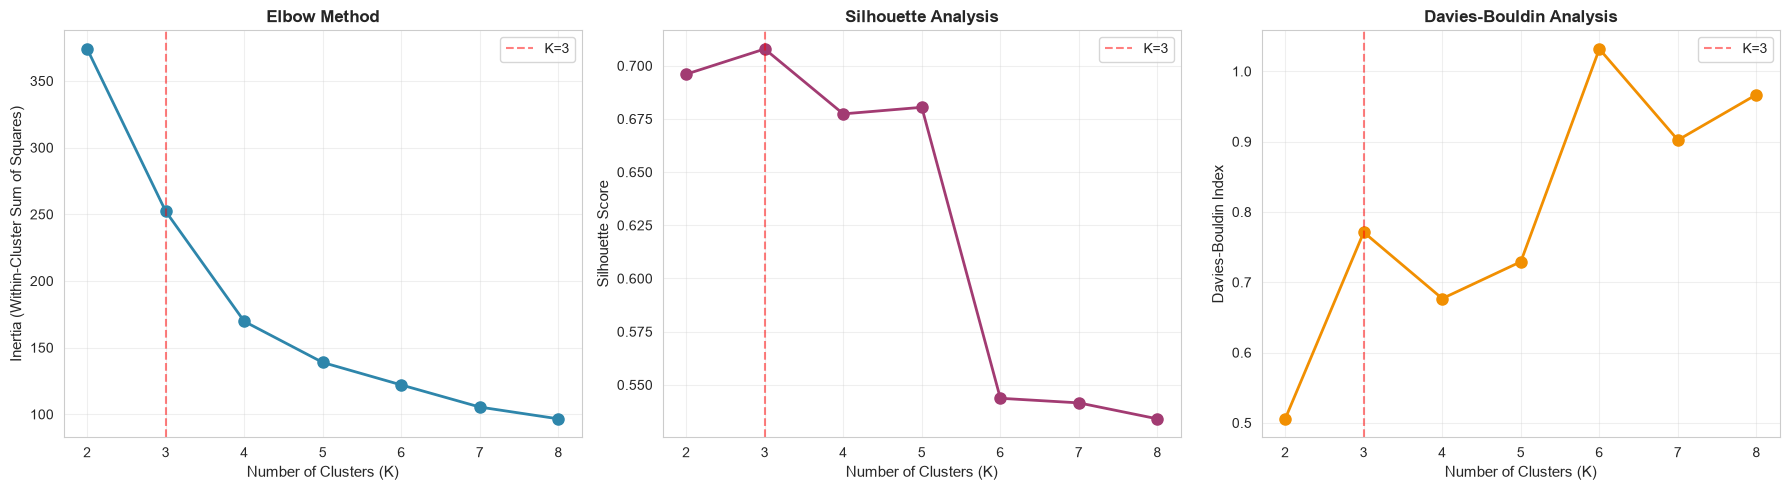


Optimal K suggestions:
Best K by Silhouette Score: 3
Best K by Davies-Bouldin Index: 2


Analysis on data WITHOUT outliers:


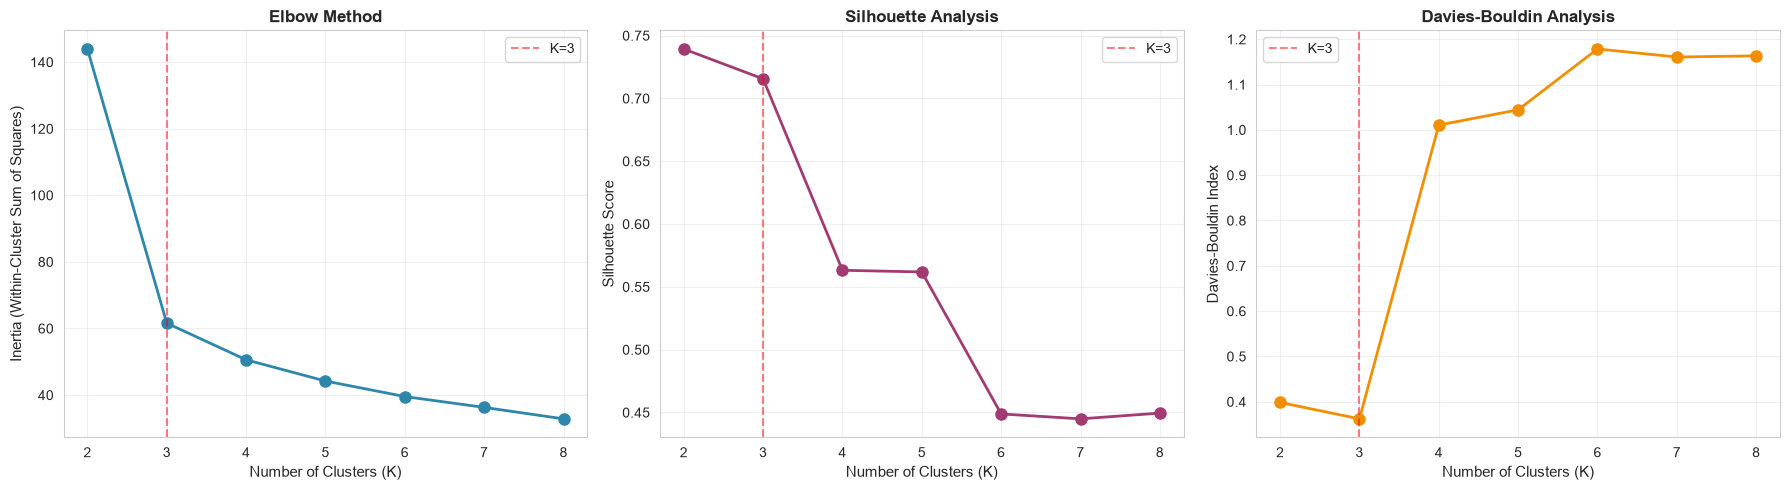


Optimal K suggestions:
Best K by Silhouette Score: 2
Best K by Davies-Bouldin Index: 3


In [15]:
def plot_elbow_analysis(X, max_k=10):
    """
    Create elbow plot and silhouette analysis for different values of K.
    """
    inertias = []
    silhouettes = []
    davies_bouldins = []
    k_range = range(2, max_k + 1)
    
    for k in k_range:
        kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
        clusters = kmeans.fit_predict(X)
        
        inertias.append(kmeans.inertia_)
        silhouettes.append(silhouette_score(X, clusters))
        davies_bouldins.append(davies_bouldin_score(X, clusters))
    
    # Create plots
    fig, axes = plt.subplots(1, 3, figsize=(18, 5))
    
    # Elbow plot
    axes[0].plot(k_range, inertias, 'o-', linewidth=2, markersize=8, color='#2E86AB')
    axes[0].set_xlabel('Number of Clusters (K)', fontsize=11)
    axes[0].set_ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=11)
    axes[0].set_title('Elbow Method', fontsize=12, fontweight='bold')
    axes[0].grid(True, alpha=0.3)
    axes[0].axvline(x=3, color='red', linestyle='--', alpha=0.5, label='K=3')
    axes[0].legend()
    
    # Silhouette score
    axes[1].plot(k_range, silhouettes, 'o-', linewidth=2, markersize=8, color='#A23B72')
    axes[1].set_xlabel('Number of Clusters (K)', fontsize=11)
    axes[1].set_ylabel('Silhouette Score', fontsize=11)
    axes[1].set_title('Silhouette Analysis', fontsize=12, fontweight='bold')
    axes[1].grid(True, alpha=0.3)
    axes[1].axvline(x=3, color='red', linestyle='--', alpha=0.5, label='K=3')
    axes[1].legend()
    
    # Davies-Bouldin index
    axes[2].plot(k_range, davies_bouldins, 'o-', linewidth=2, markersize=8, color='#F18F01')
    axes[2].set_xlabel('Number of Clusters (K)', fontsize=11)
    axes[2].set_ylabel('Davies-Bouldin Index', fontsize=11)
    axes[2].set_title('Davies-Bouldin Analysis', fontsize=12, fontweight='bold')
    axes[2].grid(True, alpha=0.3)
    axes[2].axvline(x=3, color='red', linestyle='--', alpha=0.5, label='K=3')
    axes[2].legend()
    
    plt.tight_layout()
    plt.show()
    
    # Print summary
    best_k_silhouette = list(k_range)[np.argmax(silhouettes)]
    best_k_db = list(k_range)[np.argmin(davies_bouldins)]
    
    print("\nOptimal K suggestions:")
    print(f"Best K by Silhouette Score: {best_k_silhouette}")
    print(f"Best K by Davies-Bouldin Index: {best_k_db}")

# Run analysis on cleaned data
print("Analysis on data WITH outliers:")
plot_elbow_analysis(X_scaled, max_k=8)

print("\n" + "="*80 + "\n")
print("Analysis on data WITHOUT outliers:")
plot_elbow_analysis(X_scaled_clean, max_k=8)

## 8. Visualizing the K-Means Algorithm Process

Let's visualize how K-Means iteratively refines cluster assignments and centroids.

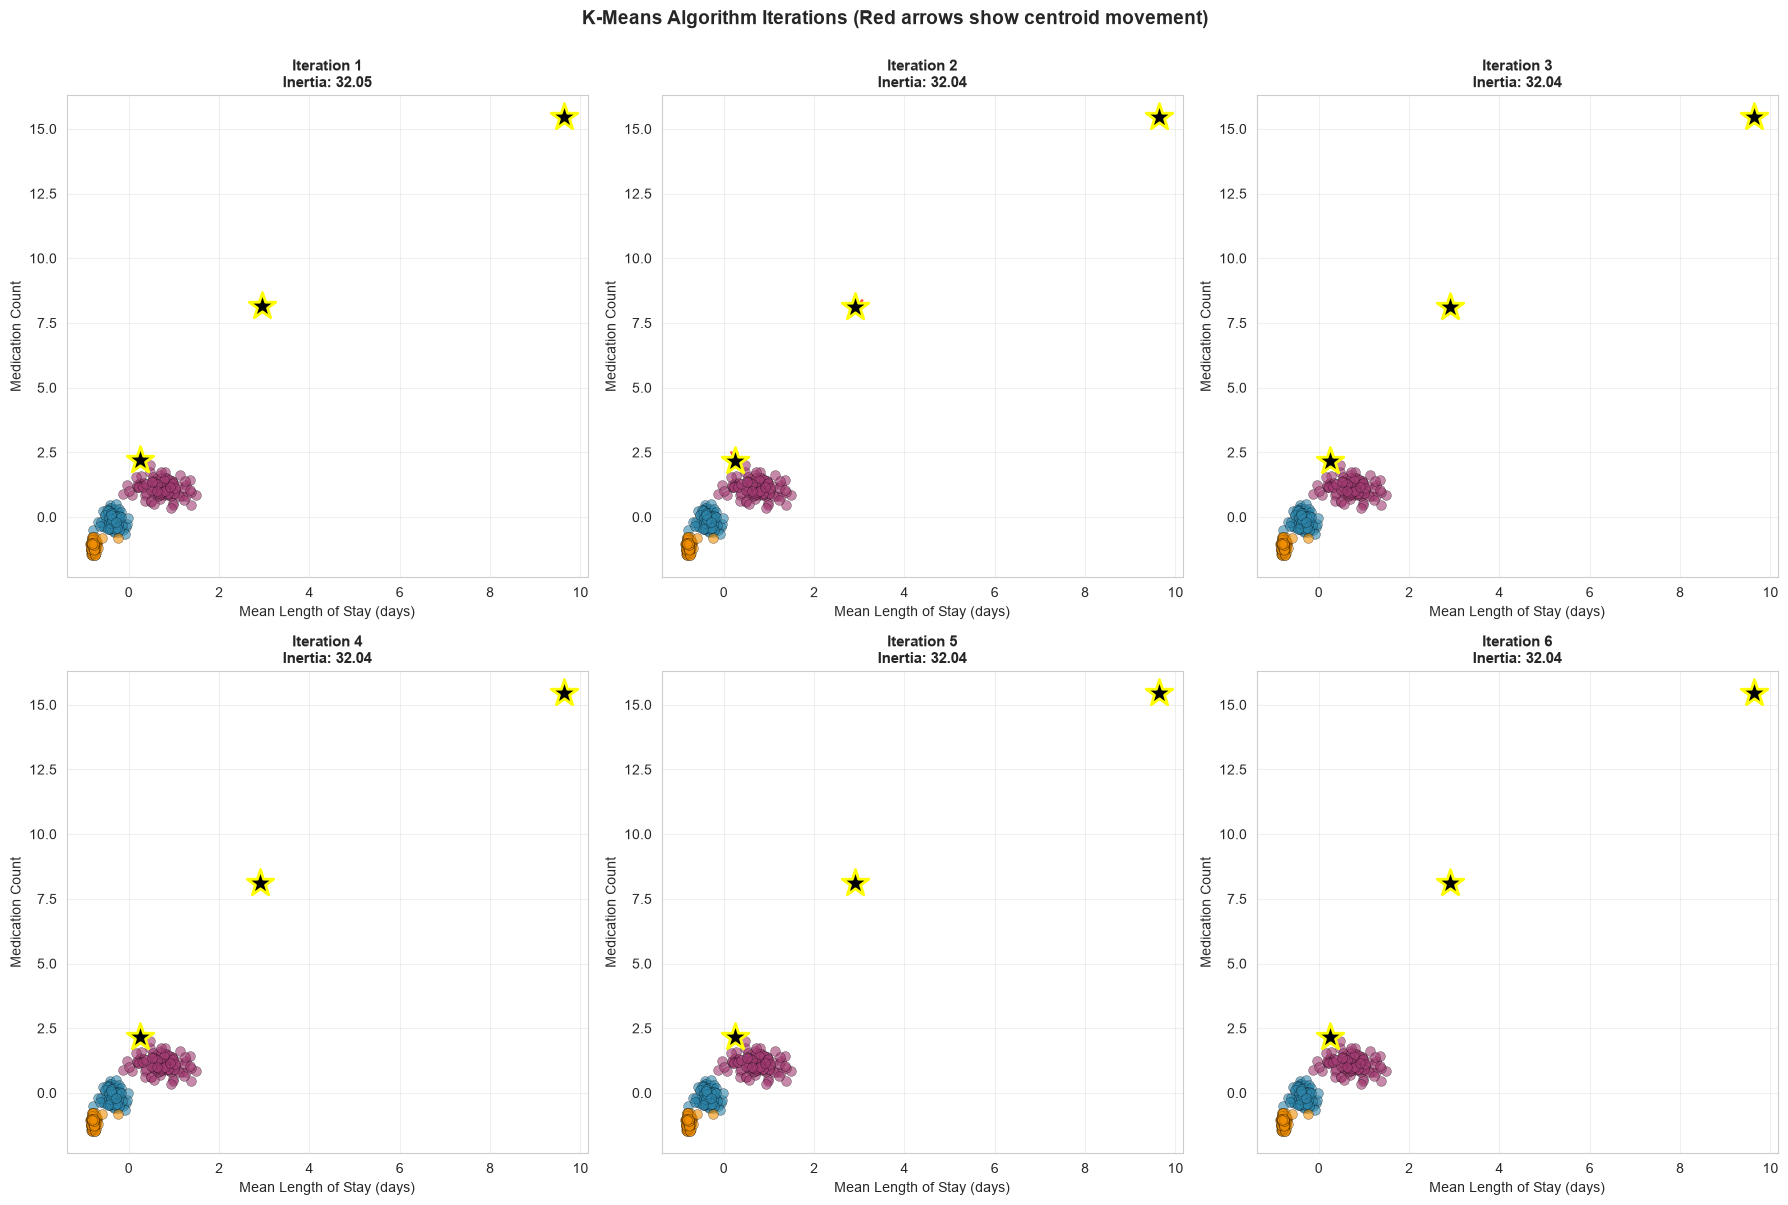

In [16]:
def visualize_kmeans_iterations(X, y, n_clusters=3, max_iter=10):
    """
    Visualize the K-Means algorithm's iterations.
    Shows first 6 iterations.
    """
    # Use only 2D data for visualization (length of stay vs medication count)
    X_2d = X[:, [1, 2]]  # length of stay and medication count columns
    feature_names = ['mean_los_days', 'medication_count']
    
    # Initialize K-Means with max_iter=1 to get each iteration
    np.random.seed(42)
    
    fig, axes = plt.subplots(2, 3, figsize=(18, 12))
    axes = axes.ravel()
    
    # Track centroids through iterations
    centroids_history = []
    
    for iteration in range(6):
        kmeans = KMeans(n_clusters=n_clusters, max_iter=iteration+1, n_init=1, random_state=42)
        labels = kmeans.fit_predict(X_2d)
        centroids = kmeans.cluster_centers_
        centroids_history.append(centroids.copy())
        
        # Plot
        colors = ['#2E86AB', '#A23B72', '#F18F01']
        
        for cluster_id in range(n_clusters):
            cluster_points = X_2d[labels == cluster_id]
            axes[iteration].scatter(cluster_points[:, 0], cluster_points[:, 1],
                                   c=colors[cluster_id], alpha=0.6, s=50,
                                   edgecolors='black', linewidth=0.3)
        
        # Plot current centroids
        centroids_orig = scaler.inverse_transform(
            np.column_stack([np.zeros((n_clusters, 1)), centroids, np.zeros((n_clusters, 1))])
        )[:, [1, 2]]
        
        axes[iteration].scatter(centroids_orig[:, 0], centroids_orig[:, 1],
                               c='black', marker='*', s=400, edgecolors='yellow',
                               linewidth=2, zorder=10)
        
        # Plot centroid movement from previous iteration
        if iteration > 0:
            prev_centroids_orig = scaler.inverse_transform(
                np.column_stack([np.zeros((n_clusters, 1)), centroids_history[iteration-1], np.zeros((n_clusters, 1))])
            )[:, [1, 2]]
            
            for c in range(n_clusters):
                axes[iteration].annotate('', xy=centroids_orig[c], xytext=prev_centroids_orig[c],
                                        arrowprops=dict(arrowstyle='->', lw=2, color='red', alpha=0.7))
        
        axes[iteration].set_xlabel('Mean Length of Stay (days)', fontsize=10)
        axes[iteration].set_ylabel('Medication Count', fontsize=10)
        axes[iteration].set_title(f'Iteration {iteration + 1}\nInertia: {kmeans.inertia_:.2f}',
                                 fontsize=11, fontweight='bold')
        axes[iteration].grid(True, alpha=0.3)
    
    plt.suptitle('K-Means Algorithm Iterations (Red arrows show centroid movement)',
                fontsize=14, fontweight='bold', y=1.00)
    plt.tight_layout()
    plt.show()

# Visualize on cleaned data
visualize_kmeans_iterations(X_scaled_clean, patient_data_clean['true_type'])

## 9. Key Takeaways and Best Practices

### Understanding Unsupervised Learning

1. **Automatic Pattern Discovery**: K-Means identifies natural groupings without labels
2. **Iterative Refinement**: The algorithm converges to stable cluster assignments
3. **No Ground Truth Required**: Useful for exploratory analysis and segmentation

### The Outlier Challenge

**Why outliers matter:**
- K-Means uses means (averages) which are sensitive to extreme values
- Outliers pull centroids away from true cluster centers
- Can result in poor cluster quality and misleading groupings

**Handling outliers:**
1. **Preprocessing**: Remove or down-weight outliers before clustering
2. **Robust algorithms**: Use median-based methods (K-Medoids) instead
3. **Outlier detection**: DBSCAN, Isolation Forest, or statistical methods
4. **Domain knowledge**: Understand what constitutes an outlier in your context - a data-entry error and a genuinely catastrophic admission look the same to the algorithm but mean very different things

### Best Practices for K-Means

**When to use K-Means:**
- ✅ Spherical, well-separated clusters expected
- ✅ Similar cluster sizes
- ✅ Large datasets (computationally efficient)
- ✅ Need interpretable cluster centers

**When NOT to use K-Means:**
- ❌ Arbitrary cluster shapes (use DBSCAN, hierarchical clustering)
- ❌ Varying cluster densities
- ❌ Many outliers (use robust methods)
- ❌ Unknown number of clusters (try hierarchical methods first)

**Implementation tips:**
1. **Always standardize features** - K-Means is sensitive to scale
2. **Try multiple initializations** - Use `n_init` parameter
3. **Validate with metrics** - Silhouette score, Davies-Bouldin index
4. **Use clinical knowledge** - Interpret cluster meanings with the care team
5. **Visualize results** - 2D projections, pair plots

### Real-World Applications in Healthcare

- **Patient segmentation**: Automatic cohorting by care-usage characteristics
- **Care management**: Targeting case-management programs at the cohorts that benefit
- **Anomaly detection**: Identifying unusual utilization or billing patterns
- **Capacity planning**: Grouping patients by expected service demand
- **Risk stratification**: Profiling cohorts before building a supervised risk model

> **Fairness caution.** Utilization reflects access to care as much as need. A cohort
> with low utilization may be under-served rather than healthy, so always check the
> demographic composition of clusters before acting on them.


## 10. Practice Exercise

Try modifying the code to:

1. **Add a new cohort** (e.g., maternity episodes with a distinctive utilization profile)
2. **Experiment with different outlier detection methods** (statistical z-score, IQR)
3. **Compare K-Means with K-Medoids** (more robust to outliers)
4. **Use PCA** to visualize high-dimensional clusters in 2D
5. **Apply to a larger synthetic population** (e.g., one generated with Synthea, an open-source synthetic patient generator)

### Challenge: Implement K-Medoids

K-Medoids uses actual data points (medoids) as cluster centers instead of means, making it more robust to outliers. Try implementing this using scikit-learn-extra or from scratch!


In [17]:
# Your code here for practice exercises


## Summary

In this notebook, we explored:

1. ✅ How K-Means automatically discovers groups in unlabeled data
2. ✅ The sensitivity of K-Means to outliers and how they distort clustering
3. ✅ Techniques for outlier detection and removal
4. ✅ Methods for determining optimal K (Elbow method, Silhouette analysis)
5. ✅ Practical application to patient utilization cohorting
6. ✅ Best practices for applying K-Means in real-world scenarios

**Key Insight**: Unsupervised learning's power lies in discovering patterns without labels, but preprocessing (especially outlier handling) is crucial for meaningful results.

**Next Steps**: Explore more robust clustering methods (DBSCAN, hierarchical clustering) and dimensionality reduction techniques (PCA, t-SNE) for complex datasets.
